# 02a Antigüedad del juego vs volumen de reseñas

**Documento relacionado:** [`docs/03-analisis-exploratorio.md`](../docs/03-analisis-exploratorio.md)

**Origen:** convertido del script `antiguedadVsResenas.py`, que se eliminó de `borradores/` al pasar a este notebook.

## Objetivo

Medir cuánto depende el número de reseñas del tiempo que lleva el juego en la tienda (sesgo de exposición), y qué tan tarde se alcanza un umbral fijo como 50 reseñas.

| Entradas | Salidas |
|---|---|
| `steam_games.csv.gz` (versión 2026-11-19) | `reports/figures/antiguedadVsResenas.png`, `reports/metrics/antiguedadVsResenas_resumen.csv` |

## Configuración

In [1]:
from pathlib import Path
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# Rutas del repositorio (el notebook vive en notebooks/)
rootDir = Path('..').resolve()
figuresDir = rootDir / 'reports' / 'figures'
metricsDir = rootDir / 'reports' / 'metrics'
processedDir = rootDir / 'data' / 'processed'
interimDir = rootDir / 'data' / 'interim'
for outPath in (figuresDir, metricsDir, processedDir, interimDir):
    outPath.mkdir(parents=True, exist_ok=True)

# Datos: versión del 2026-11-19. Se busca primero la variable de entorno STEAM_GAMES_CSV,
# luego data/raw/ y por último la carpeta Proyecto Final/Datos (fuera del repositorio).
dataCandidates = [
    Path(os.environ['STEAM_GAMES_CSV']) if 'STEAM_GAMES_CSV' in os.environ else None,
    rootDir / 'data' / 'raw' / 'steam_games.csv.gz',
    rootDir / 'data' / 'raw' / 'steam_games.csv',
    rootDir.parents[1] / 'Datos' / 'steam_games.csv.gz',
]
dataPath = next((p for p in dataCandidates if p is not None and p.exists()), None)
if dataPath is None:
    raise FileNotFoundError('No se encontró steam_games.csv(.gz); colócalo en data/raw/ o define STEAM_GAMES_CSV')
print('Datos:', dataPath.name)

snapshotDate = pd.Timestamp('2026-11-19')   # fecha de corte de la versión del dataset

# Fuente latina + respaldo CJK (macOS: Hiragino/PingFang; Linux: Noto CJK). Solo las instaladas.
installedFonts = {f.name for f in fm.fontManager.ttflist}
cjkFonts = [f for f in ('Hiragino Sans GB', 'PingFang SC', 'Arial Unicode MS', 'Noto Sans CJK SC', 'Noto Sans CJK JP')
            if f in installedFonts]
plt.rcParams['font.family'] = ['DejaVu Sans'] + cjkFonts
pd.set_option('display.width', 200)

from matplotlib.ticker import MultipleLocator, FuncFormatter

Datos: steam_games.csv.gz


## Carga y cálculo de la antigüedad

La antigüedad es el tiempo entre `release_date` y la fecha de corte (19-nov-2026), en años. Se conservan solo antigüedades entre 0 y 30 años, para dejar fuera fechas futuras o mal capturadas.

In [2]:
gamesDf = pd.read_csv(dataPath, low_memory=False)
colNames = list(gamesDf.columns)

dateCol = next(c for c in colNames if 'release' in c.lower() and 'date' in c.lower())
posCol = next(c for c in colNames if c.lower() in ('positive', 'positive_reviews', 'num_positive'))
negCol = next(c for c in colNames if c.lower() in ('negative', 'negative_reviews', 'num_negative'))
print('Usando:', dateCol, posCol, negCol)

releaseDate = pd.to_datetime(gamesDf[dateCol], errors='coerce', format='mixed')
reviewCount = pd.to_numeric(gamesDf[posCol], errors='coerce') + pd.to_numeric(gamesDf[negCol], errors='coerce')
ageYears = (snapshotDate - releaseDate).dt.days / 365.25

plotDf = pd.DataFrame({'ageYears': ageYears, 'reviewCount': reviewCount}).dropna()
plotDf = plotDf[(plotDf['ageYears'] >= 0) & (plotDf['ageYears'] <= 30)]
print(f'Juegos graficados: {len(plotDf):,} de {len(gamesDf):,}')

Usando: release_date positive negative
Juegos graficados: 150,117 de 150,199


## Estadísticos por año de antigüedad

Mediana, cuartiles, percentil 90, % con 0 reseñas y % con al menos 50 reseñas. Las curvas solo se trazan para años con al menos 30 juegos.

In [3]:
plotDf['ageBin'] = np.floor(plotDf['ageYears']).astype(int)
binStats = plotDf.groupby('ageBin')['reviewCount'].agg(
    n='size',
    median='median',
    q25=lambda s: s.quantile(0.25),
    q75=lambda s: s.quantile(0.75),
    q90=lambda s: s.quantile(0.90),
    pctZero=lambda s: (s == 0).mean() * 100,
    pctGe50=lambda s: (s >= 50).mean() * 100,
).reset_index()
binStats.to_csv(metricsDir / 'antiguedadVsResenas_resumen.csv', index=False)
minBinSize = 30  # años con menos juegos no se trazan en las curvas
binStats = binStats[binStats['n'] >= minBinSize]

spearmanRho = plotDf['ageYears'].corr(plotDf['reviewCount'], method='spearman')
print('Spearman rho:', round(spearmanRho, 3))
binStats.round(1)

Spearman rho: 0.694


,ageBin,n,median,q25,q75,q90,pctZero,pctGe50
0,0,31022,0.0,0.0,0.0,0.0,98.6,0.7
1,1,24392,0.0,0.0,2.0,25.0,70.4,7.2
2,2,19036,3.0,0.0,20.0,129.0,37.6,16.3
3,3,14263,4.0,0.0,27.0,181.0,33.5,18.6
4,4,12181,7.0,0.0,32.0,210.0,28.9,20.2
5,5,10837,11.0,1.0,46.0,327.4,20.8,24.1
6,6,8442,18.0,5.0,86.0,598.5,8.2,31.8
7,7,7242,20.0,5.0,92.0,640.9,7.5,33.3
8,8,7478,28.0,8.0,107.0,557.9,3.0,37.4
9,9,5671,42.0,13.0,175.0,829.0,1.2,47.0


## Gráfica

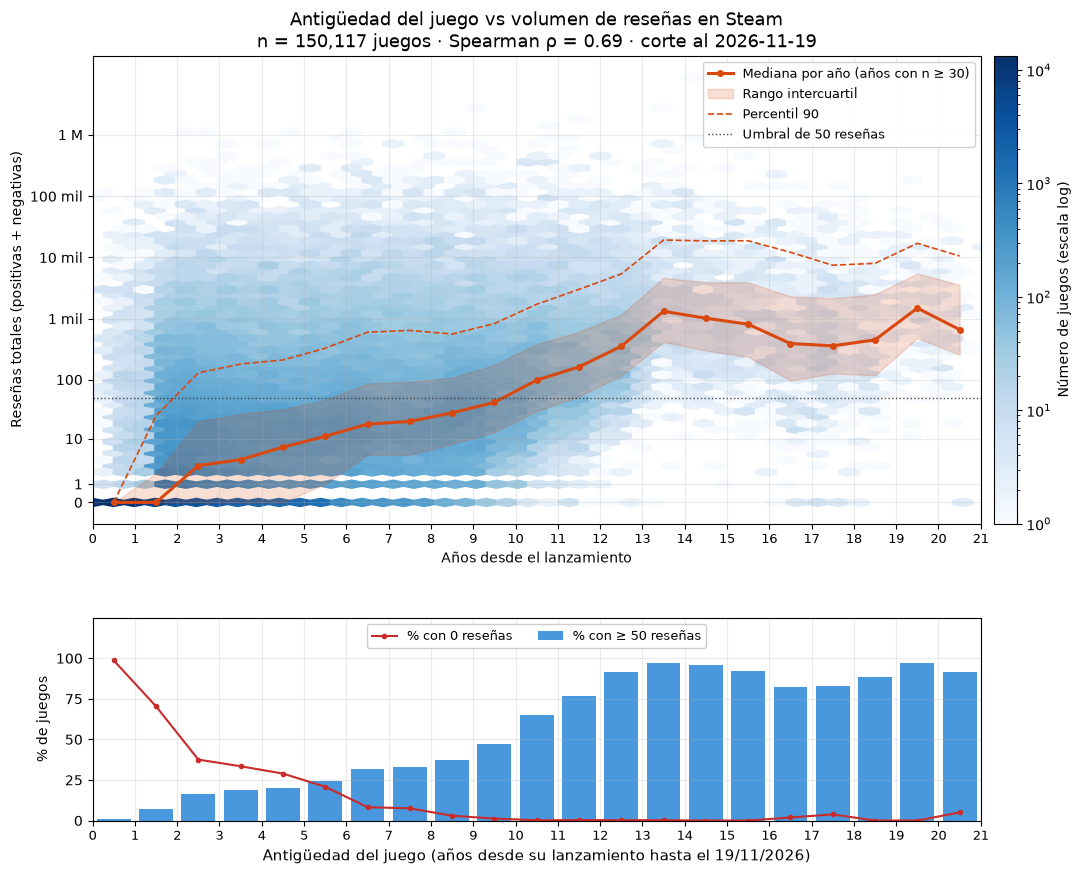

In [4]:
fig = plt.figure(figsize=(11, 9))
gridSpec = fig.add_gridspec(2, 2, height_ratios=[3, 1.3], width_ratios=[40, 1], hspace=0.28, wspace=0.03)
axMain = fig.add_subplot(gridSpec[0, 0])
axPct = fig.add_subplot(gridSpec[1, 0], sharex=axMain)
axCbar = fig.add_subplot(gridSpec[0, 1])
hb = axMain.hexbin(plotDf['ageYears'], np.log10(plotDf['reviewCount'] + 1),
                   gridsize=(60, 35), bins='log', cmap='Blues', mincnt=1)
fig.colorbar(hb, cax=axCbar, label='Número de juegos (escala log)')
binCenter = binStats['ageBin'] + 0.5
axMain.plot(binCenter, np.log10(binStats['median'] + 1), color='#D9480F', lw=2.2, marker='o', ms=4,
            label='Mediana por año (años con n ≥ 30)')
axMain.fill_between(binCenter, np.log10(binStats['q25'] + 1), np.log10(binStats['q75'] + 1),
                    color='#D9480F', alpha=0.18, label='Rango intercuartil')
axMain.plot(binCenter, np.log10(binStats['q90'] + 1), color='#D9480F', lw=1.2, ls='--', label='Percentil 90')
axMain.axhline(np.log10(51), color='#444', lw=1, ls=':', label='Umbral de 50 reseñas')
tickVals = [0, 1, 10, 100, 1_000, 10_000, 100_000, 1_000_000]
axMain.set_yticks(np.log10(np.array(tickVals) + 1))
axMain.set_yticklabels(['0', '1', '10', '100', '1 mil', '10 mil', '100 mil', '1 M'])
axMain.set_ylabel('Reseñas totales (positivas + negativas)')
axMain.set_xlabel('Años desde el lanzamiento', fontsize=10)
axMain.set_title(f'Antigüedad del juego vs volumen de reseñas en Steam\n'
                 f'n = {len(plotDf):,} juegos · Spearman ρ = {spearmanRho:.2f} · corte al {snapshotDate.date()}',
                 fontsize=13)
axMain.legend(loc='upper right', fontsize=9, framealpha=0.9)
axMain.grid(alpha=0.25)

axPct.bar(binCenter, binStats['pctGe50'], width=0.8, color='#1C7ED6', alpha=0.8, label='% con ≥ 50 reseñas')
axPct.plot(binCenter, binStats['pctZero'], color='#C92A2A', marker='o', ms=3, lw=1.5, label='% con 0 reseñas')
axPct.set_ylabel('% de juegos')
axPct.set_xlabel(f"Antigüedad del juego (años desde su lanzamiento hasta el {snapshotDate.strftime('%d/%m/%Y')})",
                 fontsize=11)
for ax in (axMain, axPct):
    ax.xaxis.set_major_locator(MultipleLocator(1))
    ax.tick_params(axis='x', labelbottom=True, labelsize=9)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, pos: f'{int(v)}'))
axPct.set_ylim(0, 125)
axPct.set_yticks([0, 25, 50, 75, 100])
axPct.set_xlim(0, binStats['ageBin'].max() + 1)
axPct.legend(loc='upper center', ncol=2, fontsize=9, framealpha=0.95)
axPct.grid(alpha=0.25)

fig.subplots_adjust(left=0.08, right=0.92, top=0.92, bottom=0.07)
fig.savefig(figuresDir / 'antiguedadVsResenas.png', dpi=160)
plt.show()

## Conclusiones del notebook

- La relación entre antigüedad y volumen de reseñas es fuerte (Spearman ρ ≈ 0.69).
- Casi todos los juegos con menos de un año (≈ 99 %) tienen 0 reseñas, y hasta los 5 años menos de 25 % llega a 50 reseñas.
- La mediana supera las 50 reseñas hasta los 9–10 años; entre los 12 y 15 años, más de 90 % de los juegos supera ese umbral.
- Un mínimo fijo de reseñas deja fuera sobre todo a los juegos recientes y carga la muestra hacia los títulos antiguos. Por eso conviene comparar contra la cohorte de lanzamiento ([02b](02b_percentiles_cohorte.ipynb)).